# Calibrate a queue model against exact truth, then export it

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sarptandoven/queuetruth/blob/main/examples/notebooks/03_calibrate_and_export.ipynb)

Every L2 backtester has a queue-model knob that is usually guessed: hftbacktest's `power_prob_queue_model3(n)`,
NautilusTrader's `prob_fill_on_limit`. This notebook fits such a parameter against what really happened in the
queue, checks it on a day it was not fitted on, and exports a snippet to paste into your backtest. The export is
fail-safe: a fit that does not beat the library default out of sample is refused (`QT-CALIB-001`), so a number
that would make the backtest worse never reaches it unmarked.

Data: queuetruth's **synthetic** dataset (CME rules, 2 instruments, 2 days). The numbers only show the workflow;
they say nothing about a real venue. Run the same cells on your own ingested order-level data for a real fit.

In [1]:
# Setup: on Colab (or anywhere queuetruth is missing) this installs it from PyPI; elsewhere it does nothing.
import importlib
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("queuetruth") is None:
    try:
        from IPython import get_ipython

        shell = get_ipython()
    except ImportError:
        shell = None
    if shell is not None:  # %pip lets Colab offer a restart when an already-imported package was upgraded
        shell.run_line_magic("pip", "install -q queuetruth pandas matplotlib")
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "queuetruth", "pandas", "matplotlib"])
    importlib.invalidate_caches()
if importlib.util.find_spec("queuetruth") is None or importlib.util.find_spec("queuetruth.frames") is None:
    raise RuntimeError(
        "this notebook needs queuetruth.frames (first released after queuetruth 0.1.1): pip install -U queuetruth"
    )

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import queuetruth as qt
from queuetruth import frames

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.5, 3.4)})

WORK = Path("qt-notebooks") / "03_calibrate"
WORK.mkdir(parents=True, exist_ok=True)
DATA = WORK / "synth"
if not (DATA / "manifest.json").exists():
    qt.fixtures_synth(str(DATA))
TRAIN, TEST = {"dates": ["2026-06-15"]}, {"dates": ["2026-06-16"]}


def hz(ns):
    """`1000000000` -> `1s`, `100000000` -> `100ms`."""
    ns = int(ns)
    return f"{ns // 10**9}s" if ns % 10**9 == 0 else f"{ns // 10**6}ms"


def export(target, cal_dir, out, force=False):
    """`qt.api.export`, with the export notes (reported as Python warnings) printed as `note:` lines."""
    with warnings.catch_warnings(record=True) as notes:
        warnings.simplefilter("always")
        ex = qt.api.export({"target": target, "calibration": {"path": str(cal_dir)}, "out": str(out), "force": force})
    for n in notes:
        print("note:", n.message)
    return ex


print("queuetruth", qt.__version__, "| synthetic data, train", TRAIN["dates"], "test", TEST["dates"])

queuetruth 0.1.1 | synthetic data, train ['2026-06-15'] test ['2026-06-16']


## 1. Shadows that look like your orders

The fit uses shadows, so place them where your strategy quotes. Here: at the touch (70%) or one tick behind
(30%), 1 or 5 lots. Every shadow rests up to 5 minutes, the longest horizon scored, so held-out metrics cover
every horizon.

In [3]:
SHADOWS = WORK / "shadows.parquet"
qt.sample_shadows(
    {
        "dataset": {"path": str(DATA)},
        "out": str(SHADOWS),
        "n": 2000,
        "seed": 0,
        "placements": [{"offset_ticks": 0, "weight": 0.7}, {"offset_ticks": -1, "weight": 0.3}],
        "qty": [{"kind": "lots", "lots": 1, "weight": 0.5}, {"kind": "lots", "lots": 5, "weight": 0.5}],
    }
)
print(len(frames.read(SHADOWS, expect="qt.shadow_spec")), "shadows")

2000 shadows


## 2. Fit hftbacktest's `power3` exponent `n`

`kind="alloc"` fits how the model shares a cancel at your price level between the queue ahead of you and behind
you, scored one cancel at a time at the exact queue state (a quasi-likelihood, with a profile interval and a
block-bootstrap interval). Then the fitted model and the library default `n = 2` both run through the zoo on the
test day.

In [4]:
power3 = qt.calibrate(
    {
        "kind": "alloc",
        "family": "power3",
        "dataset": {"path": str(DATA)},
        "shadows": {"path": str(SHADOWS)},
        "out": str(WORK / "cal-power3"),
        "train": TRAIN,
        "test": TEST,
    }
)
print(f"{power3.param_name} = {power3.estimate:.3f}  bootstrap CI {tuple(round(x, 3) for x in power3.ci_bootstrap)}")
print(f"from {power3.n_events} cancel events of {power3.n_shadows} train shadows")
print("trust:", power3.trust.verdict, power3.trust.reasons)

n = 0.564  bootstrap CI (0.508, 0.615)
from 1800 cancel events of 617 train shadows
trust: refused ['not_beating_default']


`frames.held_out` flattens the held-out comparison: one row per arm (`fitted` or `default`) and horizon, with the
trust check's per-horizon verdict. To be exported, a fit must be no worse than the default on log loss and Brier
score at every horizon and strictly better at one.

In [5]:
ho = frames.held_out(power3)
ho["horizon"] = ho["horizon_ns"].map(hz)
wide = ho.pivot(index="horizon", columns="arm", values=["logloss", "fill_rate_bias"])
wide = wide.reindex([hz(h) for h in sorted(ho["horizon_ns"].unique())])
wide["beats_default"] = ho.drop_duplicates("horizon").set_index("horizon")["beats_default"]
wide.round(5)

logloss          fill_rate_bias          beats_default
arm      default   fitted        default   fitted              
horizon                                                        
100ms    0.00000  0.00000        0.00000  0.00000           tie
1s       0.00000  0.00000       -0.00000 -0.00000           tie
10s      0.01393  0.01393       -0.00079 -0.00079           tie
60s      0.13116  0.16031       -0.00939 -0.00306         worse
300s     0.17037  0.15488       -0.01271 -0.00710        better

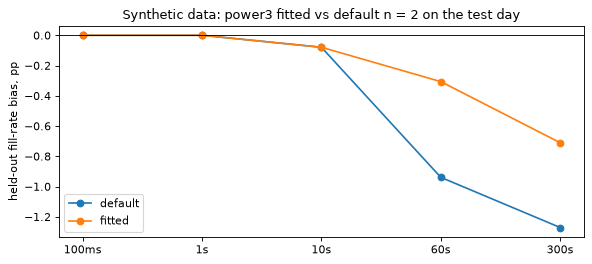

In [6]:
fig, ax = plt.subplots()
for arm, g in ho.groupby("arm"):
    ax.plot(g["horizon"], 100 * g["fill_rate_bias"], marker="o", label=f"{arm}")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("held-out fill-rate bias, pp")
ax.set_title("Synthetic data: power3 fitted vs default n = 2 on the test day")
ax.legend()
fig.tight_layout()

## 3. Export, or see why the export is refused

`export` writes the fitted value into a snippet with its provenance as comments. When the trust verdict is
`refused`, it raises `QT-CALIB-001` (exit code 1 on the command line) and says why. `force=True` writes the snippet
anyway under a `# !! NOT VALIDATED` header: for inspecting a fit, not for pasting it.

In [7]:
try:
    ex = export("hftbacktest", WORK / "cal-power3", WORK / "hbt_power3.py")
    print(ex.text)
except qt.QtError as e:
    print(f"refused: {e.code} (CLI exit code {e.exit_code})")
    print(e.message)
    forced = export("hftbacktest", WORK / "cal-power3", WORK / "hbt_power3_forced.py", force=True)
    print("\n".join(forced.text.splitlines()[:6]))

refused: QT-CALIB-001 (CLI exit code 1)
refusing to export calibration 3ad5face26d5ab3d (power3) to hftbacktest: not_beating_default: DOES NOT BEAT the default hbt_power3[exch=partial;mode=faithful;n=2] out of sample: WORSE at 60s; better at 5m; tie at 100ms, 1s, 10s (log loss at 60s: fitted 0.160308 vs default 0.131161; Brier 0.0116034 vs 0.00949367)
note: --force: writing a refused calibration (refusing to export calibration 3ad5face26d5ab3d (power3) to hftbacktest: not_beating_default: DOES NOT BEAT the default hbt_power3[exch=partial;mode=faithful;n=2] out of sample: WORSE at 60s; better at 5m; tie at 100ms, 1s, 10s (log loss at 60s: fitted 0.160308 vs default 0.131161; Brier 0.0116034 vs 0.00949367))
note: no latency calibration: keep your existing latency model (intp_order_latency line omitted).
note: NOT VALIDATED: `queuetruth export` refuses this calibration (not_beating_default); see the snippet header.
note: hftbacktest #316/#312: released versions apply partial fills of rest

A refusal is an answer, not a failure: on this data the fitted `n` is worse than the default at 60 s on the test
day (and better only at 5 minutes), so the default stays. A fit that cannot contain its own maximum is refused
too. With the search grid narrowed to
`n` between 2.7 and 7.4 (ln n from 1 to 2), the best value sits on the grid edge:

In [8]:
narrow = qt.calibrate(
    {
        "kind": "alloc",
        "family": "power3",
        "dataset": {"path": str(DATA)},
        "shadows": {"path": str(SHADOWS)},
        "out": str(WORK / "cal-narrow"),
        "train": TRAIN,
        "test": TEST,
        "grid": {"alloc": {"lo": 1.0, "hi": 2.0, "n": 21}},
    }
)
t = narrow.trust
print(f"n = {narrow.estimate:.3f}; trust {t.verdict}: reasons {t.reasons}, flags {t.flags}")
try:
    export("hftbacktest", WORK / "cal-narrow", WORK / "hbt_narrow.py")
except qt.QtError as e:
    print(f"refused: {e.code}: {e.message}")

n = 2.718; trust refused: reasons ['at_grid_edge', 'degenerate_ci', 'not_beating_default'], flags ['at_grid_edge', 'degenerate_ci', 'profile_ci_open']
refused: QT-CALIB-001: refusing to export calibration 5a938f07aeafa466 (power3) to hftbacktest: at_grid_edge: the maximum is at the lower end of the grid (n = 2.71828; grid n in [2.71828, 7.38906]); the likelihood may keep rising outside it; degenerate_ci: every bootstrap replicate gave n = 2.71828, a zero-width interval that is not a precision statement; suppressed; not_beating_default: DOES NOT BEAT the default hbt_power3[exch=partial;mode=faithful;n=2] out of sample: WORSE at 60s, 5m; tie at 100ms, 1s, 10s (log loss at 60s: fitted 0.159466 vs default 0.130473; Brier 0.0115425 vs 0.00944386)


## 4. Fit NautilusTrader's `prob_fill_on_limit`

The same workflow for NautilusTrader's touch fill model: `kind="nt_touch"` fits the probability that a touch of
your price fills you, against the exact queue.

In [9]:
ntc = qt.calibrate(
    {
        "kind": "nt_touch",
        "family": "nt_prob_touch",
        "dataset": {"path": str(DATA)},
        "shadows": {"path": str(SHADOWS)},
        "out": str(WORK / "cal-nt"),
        "train": TRAIN,
        "test": TEST,
    }
)
print(f"{ntc.param_name} = {ntc.estimate:.3f}  bootstrap CI {tuple(round(x, 3) for x in ntc.ci_bootstrap)}")
print("trust:", ntc.trust.verdict, ntc.trust.reasons, {hz(h): v for h, v in ntc.trust.beats_default.items()})
try:
    print(export("nautilus", WORK / "cal-nt", WORK / "nt_fill_model.py").text)
except qt.QtError as e:
    print(f"refused: {e.code}: {e.message}")

p = 0.529  bootstrap CI (0.51, 0.546)
trust: exportable [] {'100ms': 'better', '1s': 'better', '10s': 'better', '60s': 'better', '300s': 'better'}
note: prob_fill_on_limit is a per-touch Bernoulli probability: it is not portable across feeds with different trade-print or quote-update rates; refit per data source.
note: latency not fitted (no latency calibration in this result): no LatencyModel line is emitted; set it from your own measurements.
note: High-level BacktestVenueConfig accepts built-in fill/latency models only; pass these objects to BacktestEngine.add_venue(...) when your version requires it.
# queuetruth 0.1.1 | calibration 80d85f438b58fb81 | NautilusTrader API as documented at develop 5247ad5 (verify names
# for your version; newer builds expose FillModel under nautilus_trader.execution)
# nt_prob_touch fitted on 2026-06-15; held-out 2026-06-16; data: cme (synthetic_only, dataset c711289dad97)
# fit: p = 0.52864 (nt_touch); 1449 events from 861 shadows; bootstrap CI [0.51

## 5. Look inside a fit

Every calibration directory holds its evidence as tables. `frames.load_run` opens it: `alloc_events` holds every
cancel at a shadow's price level on both days (the queue ahead and behind at each one, and how much of it came
from ahead), `held_out/...` is the zoo run on the test day.

In [10]:
cal_run = frames.load_run(WORK / "cal-power3")
print(cal_run)
print("tables:", list(cal_run))
events = cal_run["alloc_events"]
print(len(events), "alloc events on both days; columns:", list(events.columns))
# The rows the power3 fit scored: the train day, with queue both ahead of and behind the shadow.
train_day = pd.Timestamp(TRAIN["dates"][0]).date()
fit_rows = events[(events["session_date"] == train_day) & (events["front"] > 0) & (events["back"] > 0)]
assert len(fit_rows) == power3.n_events
print(len(fit_rows), "of them are the train-day events the fit scored")

RunFrames(qt.calibration_result run_id=3ad5face26d5ab3d, 5 tables, backend=pandas: qt-notebooks/03_calibrate/cal-power3)
tables: ['alloc_events', 'held_out/zoo_predictions', 'held_out/zoo_shadows', 'held_out/zoo_trajectory', 'touch_records']
5595 alloc events on both days; columns: ['shadow_id', 'instrument_id', 'session_date', 'ts_event', 'front', 'back', 'ahead_cancel', 'behind_cancel', 'l2_prev', 'l2_new', 'l2_trades']
1800 of them are the train-day events the fit scored


What the fit sees: where in the queue the cancelled quantity sat. Grouping the fit's events by the shadow's relative
position (`front / (front + back)`, 0 = at the head of the queue), the share of cancelled quantity that came from
ahead of the shadow is the curve a queue model's cancel allocation has to reproduce.

In [11]:
pos = fit_rows.copy()
pos["position"] = pd.cut(pos["front"] / (pos["front"] + pos["back"]), [0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)
g = pos.groupby("position", observed=True)[["ahead_cancel", "behind_cancel"]].sum()
g["share_ahead"] = g["ahead_cancel"] / (g["ahead_cancel"] + g["behind_cancel"])
g.assign(events=pos.groupby("position", observed=True).size()).round(3)

,ahead_cancel,behind_cancel,share_ahead,events
position,,,,
"(-0.001, 0.2]",345.0,1018.0,0.253,410
"(0.2, 0.4]",768.0,726.0,0.514,419
"(0.4, 0.6]",847.0,354.0,0.705,336
"(0.6, 0.8]",1046.0,246.0,0.810,338
"(0.8, 1.0]",1095.0,76.0,0.935,297


## On your own data

Replace the dataset with yours (`queuetruth ingest --format itch|dbn|coinbase|... --out my-ds`), place shadows
where you quote, and train and test on different days (or `{"blocks": {"index": [...], "n_blocks": 5}}` windows
within one day). The command-line equivalents are `queuetruth calibrate alloc|nt-touch ...` and
`queuetruth export hftbacktest|nautilus --calibration ...`; the how-to *Calibrate my hftbacktest queue model* in
the documentation has the full recipe, and [02](02_nautilus_too_optimistic.ipynb) runs the NautilusTrader fit on
real Nasdaq data.